In [1]:
! pip install chembl_webresource_client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.3 MB/s eta 0:00:00


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

**Target Protein inhibitor - Human immunodeficiency virus type 1 protease**

We are using ChEMBL dataset - https://www.ebi.ac.uk/chembl/explore/target/CHEMBL243 to get the set of drug molecules and their reaction to inhibit the virus.


In [3]:
from chembl_webresource_client.new_client import new_client

selected_target = "CHEMBL243"

targets = pd.DataFrame.from_dict(
    new_client.target.filter(target_chembl_id=selected_target))
print(targets[["target_chembl_id", "pref_name", "organism", "target_type"]])

activities = new_client.activity.filter(
    target_chembl_id=selected_target).filter(standard_type="IC50")
df = pd.DataFrame.from_dict(activities)

print(df.shape)
df.to_csv("hiv1_protease_01_bioactivity_raw.csv", index=False)
df.head()

  target_chembl_id                                     pref_name  \
0        CHEMBL243  Human immunodeficiency virus type 1 protease   

                         organism     target_type  
0  Human immunodeficiency virus 1  SINGLE PROTEIN  
(3555, 47)


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32165,[],CHEMBL763424,Inhibitory concentration against HIV-1 Proteas...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,ug ml-1,UO_0000274,None,30.0
1,None,None,32166,[],CHEMBL763424,Inhibitory concentration against HIV-1 Proteas...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,ug ml-1,UO_0000274,None,93.0
2,None,None,32456,[],CHEMBL769366,In vivo antiviral activity (IC50) against HIV-...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,42.0
3,None,None,32459,[],CHEMBL769366,In vivo antiviral activity (IC50) against HIV-...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,1000.0
4,None,None,33353,[],CHEMBL696055,Inhibitory activity was determined against HIV...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,4.0


Checking for missing data and clearning them out

In [4]:
df2 = df[df.standard_value.notna() & df.canonical_smiles.notna()].copy()
df2

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32165,[],CHEMBL763424,Inhibitory concentration against HIV-1 Proteas...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,ug ml-1,UO_0000274,None,30.0
1,None,None,32166,[],CHEMBL763424,Inhibitory concentration against HIV-1 Proteas...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,ug ml-1,UO_0000274,None,93.0
2,None,None,32456,[],CHEMBL769366,In vivo antiviral activity (IC50) against HIV-...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,42.0
3,None,None,32459,[],CHEMBL769366,In vivo antiviral activity (IC50) against HIV-...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,1000.0
4,None,None,33353,[],CHEMBL696055,Inhibitory activity was determined against HIV...,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3550,"{'action_type': 'INHIBITOR', 'description': 'N...",None,25848693,[],CHEMBL5506286,Inhibition of HIV-1 protease,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,6.0
3551,"{'action_type': 'INHIBITOR', 'description': 'N...",None,25848694,[],CHEMBL5506286,Inhibition of HIV-1 protease,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,10.0
3552,"{'action_type': 'INHIBITOR', 'description': 'N...",None,25848695,[],CHEMBL5506286,Inhibition of HIV-1 protease,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,nM,UO_0000065,None,10.0
3553,"{'action_type': 'INHIBITOR', 'description': 'N...",None,25951872,[],CHEMBL5537228,Inhibition of HIV-1 protease,B,None,None,BAO_0000190,...,Human immunodeficiency virus 1,Human immunodeficiency virus type 1 protease,11676,None,None,IC50,uM,UO_0000065,None,4.3


In [5]:
len(df2.canonical_smiles.unique())

2824

Removing duplicate canonical smiles

In [6]:
df2 = df2[(df2.standard_units == "nM") & (df2.standard_relation == "=")].copy()
df2["standard_value"] = df2.standard_value.astype(float)
df2 = df2[df2.standard_value > 0]
df2 = df2.drop_duplicates("canonical_smiles")      # keep first record per compound

print("unique compounds:", len(df2))
df2.shape

unique compounds: 2577


(2577, 47)

In [7]:
df2.to_csv("hiv1_protease_df2_cleaned.csv", index=False)
print("Saved:", df2.shape)

Saved: (2577, 47)


The bioactivity data is the IC50 value. Compounds having values of less than 1000 nM will be considered to be active while those greater than 10,000 nM will be considered to be inactive. As for those values between 1,000 and 10,000 nM will be referred to as intermediate.

In [8]:
df3 = df2[["molecule_chembl_id", "canonical_smiles", "standard_value"]].copy().reset_index(drop=True)

# 2-class
df3["class_2"] = np.where(df3.standard_value < 10000, "active", "inactive")

# 3-class
def label3(v):
    if v >= 10000: return "inactive"
    if v <= 1000:  return "active"
    return "intermediate"

df3["class_3"] = df3.standard_value.apply(label3)

# Integer targets used by the models
df3["y_2"] = (df3.class_2 == "active").astype(int)                                   # 0 inactive, 1 active
df3["y_3"] = df3.class_3.map({"inactive": 0, "intermediate": 1, "active": 2})         # 0, 1, 2

print("2-class:\n", df3.class_2.value_counts(), "\n")
print("3-class:\n", df3.class_3.value_counts())

2-class:
 class_2
active      2364
inactive     213
Name: count, dtype: int64 

3-class:
 class_3
active          2016
intermediate     348
inactive         213
Name: count, dtype: int64


In [9]:
# Or separate files, one per task
df3[["molecule_chembl_id", "canonical_smiles", "standard_value", "class_2", "y_2"]].to_csv(
    "hiv1_protease_df3_2class.csv", index=False)
df3[["molecule_chembl_id", "canonical_smiles", "standard_value", "class_3", "y_3"]].to_csv(
    "hiv1_protease_df3_3class.csv", index=False)

print("Saved:", df3.shape)

Saved: (2577, 7)


In [10]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 55.0 MB/s eta 0:00:00


In [11]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

def lipinski(smiles_list):
    rows = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        if m is None:
            rows.append([np.nan]*4); continue
        rows.append([Descriptors.MolWt(m), Descriptors.MolLogP(m),
                     Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m)])
    return pd.DataFrame(rows, columns=["MW", "LogP", "NumHDonors", "NumHAcceptors"])

df4 = pd.concat([df3, lipinski(df3.canonical_smiles)], axis=1).dropna().reset_index(drop=True)

df4["pIC50"] = 9 - np.log10(df4.standard_value.clip(upper=1e8))

# df5 must be created BEFORE it is used below
df5 = df4.copy()
df5.to_csv("hiv1_protease_curated.csv", index=False)

# Save SMILES + pIC50 (with ID and IC50 for reference)
pic50_df = df5[["molecule_chembl_id", "canonical_smiles", "standard_value", "pIC50"]].copy()
pic50_df.to_csv("hiv1_protease_pIC50.csv", index=False)

print(df5.shape)
print("Saved pIC50 file:", pic50_df.shape)
df5.head()

(2577, 12)
Saved pIC50 file: (2577, 4)


,molecule_chembl_id,canonical_smiles,standard_value,class_2,class_3,y_2,y_3,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL108102,COC(=O)N[C@H](C(=O)N[C@@H](Cc1ccccc1)C(O)CN(Cc...,42.0,active,active,1,2,617.719,2.50850,5,8,7.376751
1,CHEMBL20143,CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc...,4.0,active,active,1,2,681.733,4.67370,4,7,8.397940
2,CHEMBL75310,Cc1ccc(CN2CCN(C[C@@H](O)[C@H](Cc3ccccc3)NC(=O)...,2.0,active,active,1,2,657.878,2.70102,3,9,8.698970
3,CHEMBL19545,CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc...,6.0,active,active,1,2,737.841,5.93080,3,8,8.221849
4,CHEMBL320783,COC(=O)NC(C(=O)NN(Cc1ccc(OC)cc1)C[C@H](O)[C@H]...,31.0,active,active,1,2,741.846,2.21960,6,10,7.508638


**Data Analysis - Lipsinki descriptors.**

An orally active drug-like compound should not have more than one violation. The Lipinski's Rule stated the following:



1.   Molecular weight (MW) < 500 Dalton
2.   Octanol-water partition coefficient (LogP) < 5
3.   Hydrogen bond donors (NumHDonors) < 5
4.   Hydrogen bond acceptors < 10


**Statistical analysis | Mann-Whitney U Test or Kruskal-Wallis**

The Mann-Whitney U test [5] is a nonparametric statistical significance test for determining whether two independent samples were drawn from a population with the same distribution.

For 3 groups, we use Kruskal-Wallis test

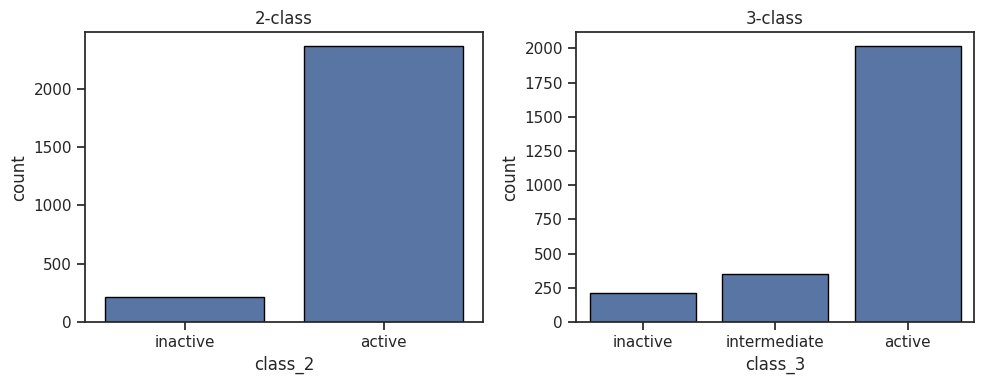

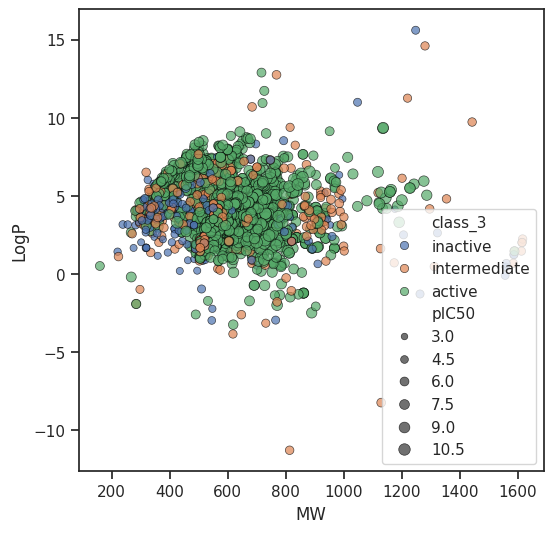

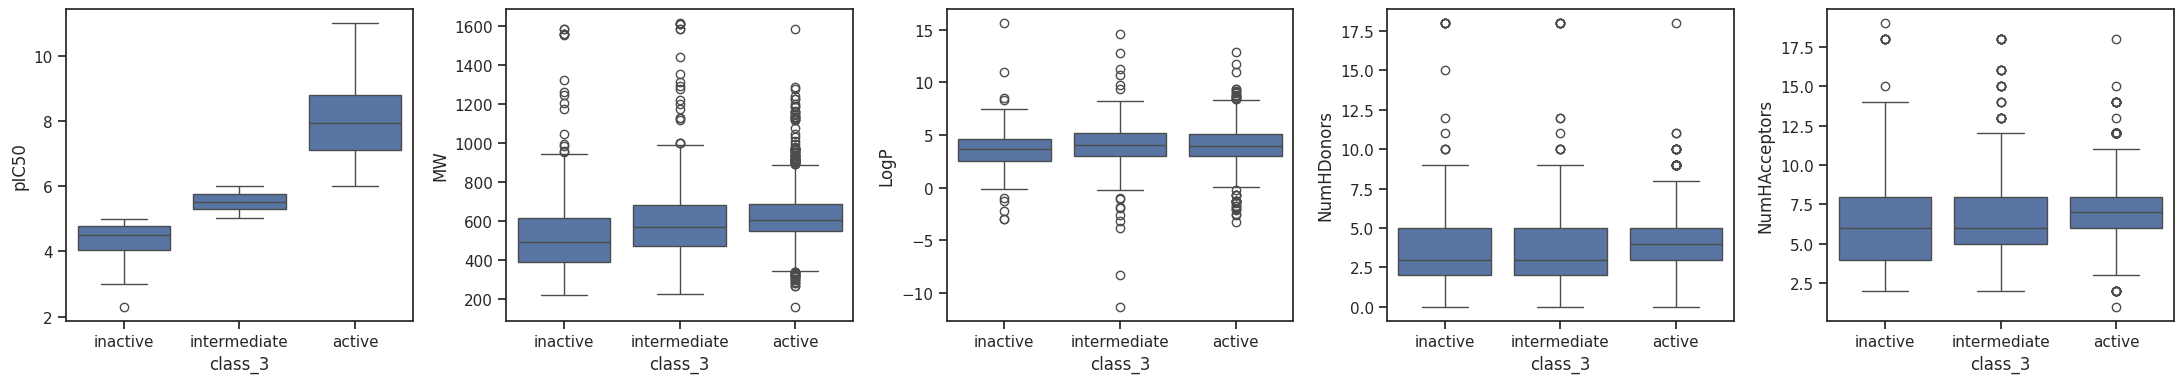

2-class (Mann-Whitney U):
  MW              p=3.45e-19  -> different
  LogP            p=6.78e-04  -> different
  NumHDonors      p=1.56e-04  -> different
  NumHAcceptors   p=6.88e-13  -> different

3-class (Kruskal-Wallis):
  MW              p=9.74e-24  -> different
  LogP            p=3.06e-03  -> different
  NumHDonors      p=2.91e-07  -> different
  NumHAcceptors   p=2.40e-14  -> different


In [12]:
sns.set(style="ticks")
order2 = ["inactive", "active"]
order3 = ["inactive", "intermediate", "active"]

# Class counts for both label sets
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="class_2", data=df5, order=order2, edgecolor="black", ax=axes[0])
axes[0].set_title("2-class")
sns.countplot(x="class_3", data=df5, order=order3, edgecolor="black", ax=axes[1])
axes[1].set_title("3-class")
plt.tight_layout(); plt.show()

# MW vs LogP, colored by the 3-class label
plt.figure(figsize=(6, 6))
sns.scatterplot(x="MW", y="LogP", data=df5, hue="class_3", hue_order=order3,
                size="pIC50", edgecolor="black", alpha=0.7)
plt.show()

# Boxplots per descriptor, 3-class
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, ["pIC50", "MW", "LogP", "NumHDonors", "NumHAcceptors"]):
    sns.boxplot(x="class_3", y=col, data=df5, order=order3, ax=ax)
plt.tight_layout(); plt.show()

# Statistical tests
from scipy.stats import mannwhitneyu, kruskal

print("2-class (Mann-Whitney U):")
for col in ["MW", "LogP", "NumHDonors", "NumHAcceptors"]:
    a = df5[df5.class_2 == "active"][col]
    i = df5[df5.class_2 == "inactive"][col]
    _, p = mannwhitneyu(a, i)
    print(f"  {col:15s} p={p:.2e}  ->", "different" if p < 0.05 else "same")

print("\n3-class (Kruskal-Wallis):")
for col in ["MW", "LogP", "NumHDonors", "NumHAcceptors"]:
    groups = [df5[df5.class_3 == c][col] for c in order3]
    _, p = kruskal(*groups)
    print(f"  {col:15s} p={p:.2e}  ->", "different" if p < 0.05 else "same")

**Generating PaDEL Fingerprints from SMILES**

In [13]:
df5[["canonical_smiles", "molecule_chembl_id"]].to_csv(
    "molecule.smi", sep="\t", index=False, header=False)

In [14]:
! wget https://github.com/dataprofessor/bioinformatics/raw/padel/padel.zip
! wget https://github.com/dataprofessor/bioinformatics/raw/padel/padel.sh

--2026-10-10 23:26:57--  https://github.com/dataprofessor/bioinformatics/raw/padel/padel.zip
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/dataprofessor/bioinformatics/padel/padel.zip [following]
--2026-10-10 23:26:59--  https://raw.githubusercontent.com/dataprofessor/bioinformatics/padel/padel.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 25768637 (25M) [application/zip]
Saving to: ‘padel.zip’

padel.zip           100%[===================>]  24.57M   148MB/s    in 0.2s    

2026-10-10 23:27:00 (148 MB/s) - ‘padel.zip’ saved [25768637/25768637]

--2026-10-10 23:27:00--  https://github.co

In [15]:
! unzip padel.zip

Archive:  padel.zip
   creating: PaDEL-Descriptor/
  inflating: __MACOSX/._PaDEL-Descriptor  
  inflating: PaDEL-Descriptor/MACCSFingerprinter.xml  
  inflating: __MACOSX/PaDEL-Descriptor/._MACCSFingerprinter.xml  
  inflating: PaDEL-Descriptor/AtomPairs2DFingerprinter.xml  
  inflating: __MACOSX/PaDEL-Descriptor/._AtomPairs2DFingerprinter.xml  
  inflating: PaDEL-Descriptor/EStateFingerprinter.xml  
  inflating: __MACOSX/PaDEL-Descriptor/._EStateFingerprinter.xml  
  inflating: PaDEL-Descriptor/Fingerprinter.xml  
  inflating: __MACOSX/PaDEL-Descriptor/._Fingerprinter.xml  
  inflating: PaDEL-Descriptor/.DS_Store  
  inflating: __MACOSX/PaDEL-Descriptor/._.DS_Store  
   creating: PaDEL-Descriptor/license/
  inflating: __MACOSX/PaDEL-Descriptor/._license  
  inflating: PaDEL-Descriptor/KlekotaRothFingerprintCount.xml  
  inflating: __MACOSX/PaDEL-Descriptor/._KlekotaRothFingerprintCount.xml  
  inflating: PaDEL-Descriptor/config  
  inflating: __MACOSX/PaDEL-Descriptor/._config  
  inf

In [16]:
! cat molecule.smi | head -5

COC(=O)N[C@H](C(=O)N[C@@H](Cc1ccccc1)C(O)CN(Cc1ccc(F)cc1)NC(=O)[C@@H](NC(=O)OC)C(C)C)C(C)C	CHEMBL108102
CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N[C@@H](C(=O)O)C(C)C	CHEMBL20143
Cc1ccc(CN2CCN(C[C@@H](O)[C@H](Cc3ccccc3)NC(=O)O[C@@H]3CCS(=O)(=O)[C@@H]3C(C)C)[C@H](C(=O)NC(C)(C)C)C2)cn1	CHEMBL75310
CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N[C@@H](C(=O)OC(C)(C)C)C(C)C	CHEMBL19545
COC(=O)NC(C(=O)NN(Cc1ccc(OC)cc1)C[C@H](O)[C@H](Cc1ccccc1)NC(=O)[C@H](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)C	CHEMBL320783


In [17]:
! cat molecule.smi | wc -l

2577


In [18]:
! cat padel.sh

java -Xms1G -Xmx1G -Djava.awt.headless=true -jar ./PaDEL-Descriptor/PaDEL-Descriptor.jar -removesalt -standardizenitro -fingerprints -descriptortypes ./PaDEL-Descriptor/PubchemFingerprinter.xml -dir ./ -file descriptors_output.csv


In [19]:
! bash padel.sh

[0.022s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.022s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Processing CHEMBL108102 in molecule.smi (1/2577). 
Processing CHEMBL20143 in molecule.smi (2/2577). 
Processing CHEMBL75310 in molecule.smi (3/2577). Average speed: 6.01 s/mol.
Processing CHEMBL19545 in molecule.smi (4/2577). Average speed: 6.36 s/mol.
Processing CHEMBL320783 in molecule.smi (5/2577). Average speed: 3.42 s/mol.
Processing CHEMBL309346 in molecule.smi (6/2577). Average speed: 1.94 s/mol.
Processing CHEMBL308574 in molecule.smi (7/2577). Average speed: 1.57 s/mol.
Processing CHEMBL325815 in molecule.smi (8/2577). Average speed: 1.46 s/mol.
Processing CHEMBL108807 in molecule.smi (9/2577). Average speed: 1.49 s/mol.
Processing CHEMBL76460 in molecul

In [20]:
! ls -l

total 34944
-rw-r--r-- 1 root root  4590588 Oct 10 23:39 descriptors_output.csv
-rw-r--r-- 1 root root  2128646 Oct 10 23:26 hiv1_protease_01_bioactivity_raw.csv
-rw-r--r-- 1 root root   472435 Oct 10 23:26 hiv1_protease_curated.csv
-rw-r--r-- 1 root root  1597633 Oct 10 23:26 hiv1_protease_df2_cleaned.csv
-rw-r--r-- 1 root root   300641 Oct 10 23:26 hiv1_protease_df3_2class.csv
-rw-r--r-- 1 root root   302729 Oct 10 23:26 hiv1_protease_df3_3class.csv
-rw-r--r-- 1 root root   322155 Oct 10 23:26 hiv1_protease_pIC50.csv
drwxr-xr-x 3 root root     4096 Oct 10 23:27 __MACOSX
-rw-r--r-- 1 root root   262490 Oct 10 23:26 molecule.smi
drwxrwxr-x 4 root root     4096 May 30  2020 PaDEL-Descriptor
-rw-r--r-- 1 root root      231 Oct 10 23:27 padel.sh
-rw-r--r-- 1 root root 25768637 Oct 10 23:27 padel.zip
drwxr-xr-x 1 root root     4096 Oct  2 13:50 sample_data


In [21]:
df_temp_X = pd.read_csv('descriptors_output.csv')
df_temp_X

,Name,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,CHEMBL108102,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CHEMBL20143,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,CHEMBL75310,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,CHEMBL19545,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,CHEMBL320783,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2572,CHEMBL5415656,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2573,CHEMBL1230778,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2574,CHEMBL5561690,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2575,CHEMBL5560565,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [22]:
# Load PaDEL output
fp = pd.read_csv("descriptors_output.csv")
print("PaDEL output:", fp.shape)

# Merge with your curated data on ChEMBL ID (PaDEL's "Name" column holds the ID)
data = df5.merge(fp, left_on="molecule_chembl_id", right_on="Name").drop(columns=["Name"])
fp_cols = [c for c in data.columns if c.startswith("PubchemFP")]
print("Merged:", data.shape, "| fingerprint columns:", len(fp_cols))

# Build the final table
id_cols     = ["molecule_chembl_id", "canonical_smiles"]
target_cols = ["pIC50", "class_2", "y_2", "class_3", "y_3"]

final_df = data[id_cols + fp_cols + target_cols].copy()
final_df = final_df.rename(columns={"class_2": "binary_class",
                                    "y_2": "binary_label",
                                    "class_3": "three_class",
                                    "y_3": "three_class_label"})

final_df.to_csv("hiv1_protease_padel_full.csv", index=False)
print("Saved:", final_df.shape)
final_df.iloc[:, [0, 1, 2, 3, -5, -4, -3, -2, -1]].head()

PaDEL output: (2577, 882)
Merged: (2577, 893) | fingerprint columns: 881
Saved: (2577, 888)


,molecule_chembl_id,canonical_smiles,PubchemFP0,PubchemFP1,pIC50,binary_class,binary_label,three_class,three_class_label
0,CHEMBL108102,COC(=O)N[C@H](C(=O)N[C@@H](Cc1ccccc1)C(O)CN(Cc...,1,1,7.376751,active,1,active,2
1,CHEMBL20143,CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc...,1,1,8.397940,active,1,active,2
2,CHEMBL75310,Cc1ccc(CN2CCN(C[C@@H](O)[C@H](Cc3ccccc3)NC(=O)...,1,1,8.698970,active,1,active,2
3,CHEMBL19545,CC(C)[C@H](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc...,1,1,8.221849,active,1,active,2
4,CHEMBL320783,COC(=O)NC(C(=O)NN(Cc1ccc(OC)cc1)C[C@H](O)[C@H]...,1,1,7.508638,active,1,active,2


In [23]:
import os
from google.colab import files
import zipfile

# List of key files generated in this session to download
files_to_download = [
    'descriptors_output.csv',
    'hiv1_protease_01_bioactivity_raw.csv',
    'hiv1_protease_curated.csv',
    'hiv1_protease_df2_cleaned.csv',
    'hiv1_protease_df3_2class.csv',
    'hiv1_protease_df3_3class.csv',
    'hiv1_protease_pIC50.csv',
    'molecule.smi',
    'padel.sh',
    'hiv1_protease_padel_full.csv'
]

# Filter only files that actually exist
existing_files = [f for f in files_to_download if os.path.exists(f)]

if existing_files:
    zip_filename = 'session_files.zip'
    with zipfile.ZipFile(zip_filename, 'w') as zipf:
        for f in existing_files:
            zipf.write(f)
    print(f'Created {zip_filename} with {len(existing_files)} files.')
    files.download(zip_filename)
else:
    print('No generated files found to download.')

Created session_files.zip with 10 files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>